# Credit Card Customer Segmentation
## 1. Data Exploration

**Objective:** Understand the structure, features, and quality of the credit card customer dataset before applying K-Means clustering.


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Locate the dataset
possible_paths = [
    Path("../data/raw/CC GENERAL.csv"),
    Path("data/raw/CC GENERAL.csv")
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError("CC GENERAL.csv not found.")

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## 2. Dataset Structure and Data Quality

This section examines the dataset's schema, data types, missing values, duplicate records, and unique values.

In [2]:
# 1. Display column names
print("COLUMNS IN DATASET:")
print(df.columns.tolist())

# 2. Dataset information
print("\nDATASET INFORMATION:")
df.info()

# 3. Missing values and unique values
data_quality = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

print("\nDATA QUALITY REPORT:")
display(data_quality)

# 4. Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

COLUMNS IN DATASET:
['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH

,Data Type,Missing Values,Missing Percentage,Unique Values
CUST_ID,str,0,0.00,8950
BALANCE,float64,0,0.00,8871
BALANCE_FREQUENCY,float64,0,0.00,43
PURCHASES,float64,0,0.00,6203
ONEOFF_PURCHASES,float64,0,0.00,4014
INSTALLMENTS_PURCHASES,float64,0,0.00,4452
CASH_ADVANCE,float64,0,0.00,4323
PURCHASES_FREQUENCY,float64,0,0.00,47
ONEOFF_PURCHASES_FREQUENCY,float64,0,0.00,47
PURCHASES_INSTALLMENTS_FREQUENCY,float64,0,0.00,47



Duplicate Records: 0


## 3. Descriptive Statistical Analysis

This section examines the central tendency, dispersion, range, and distribution of numerical customer attributes.

In [3]:
# Descriptive statistics
print("DESCRIPTIVE STATISTICS")
display(df.describe().T)

# Skewness of numerical features
print("\nFEATURE SKEWNESS")
skewness = df.select_dtypes(include=np.number).skew().sort_values(
    ascending=False
)

display(skewness.to_frame(name="Skewness"))

# Check numerical columns with zero variance
print("\nZERO VARIANCE FEATURES")
print(df.select_dtypes(include=np.number).var()[
    df.select_dtypes(include=np.number).var() == 0
])

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000



FEATURE SKEWNESS


,Skewness
MINIMUM_PAYMENTS,13.622797
ONEOFF_PURCHASES,10.045083
PURCHASES,8.144269
INSTALLMENTS_PURCHASES,7.299120
PAYMENTS,5.907620
CASH_ADVANCE_TRX,5.721298
CASH_ADVANCE,5.166609
PURCHASES_TRX,4.630655
BALANCE,2.393386
PRC_FULL_PAYMENT,1.942820



ZERO VARIANCE FEATURES
Series([], dtype: float64)


## 4. Feature Distribution Analysis

Visualize the distributions of monetary and transaction-related features using a logarithmic transformation for easier comparison.

The transformation is applied only for visualization at this stage. The original dataset remains unchanged.

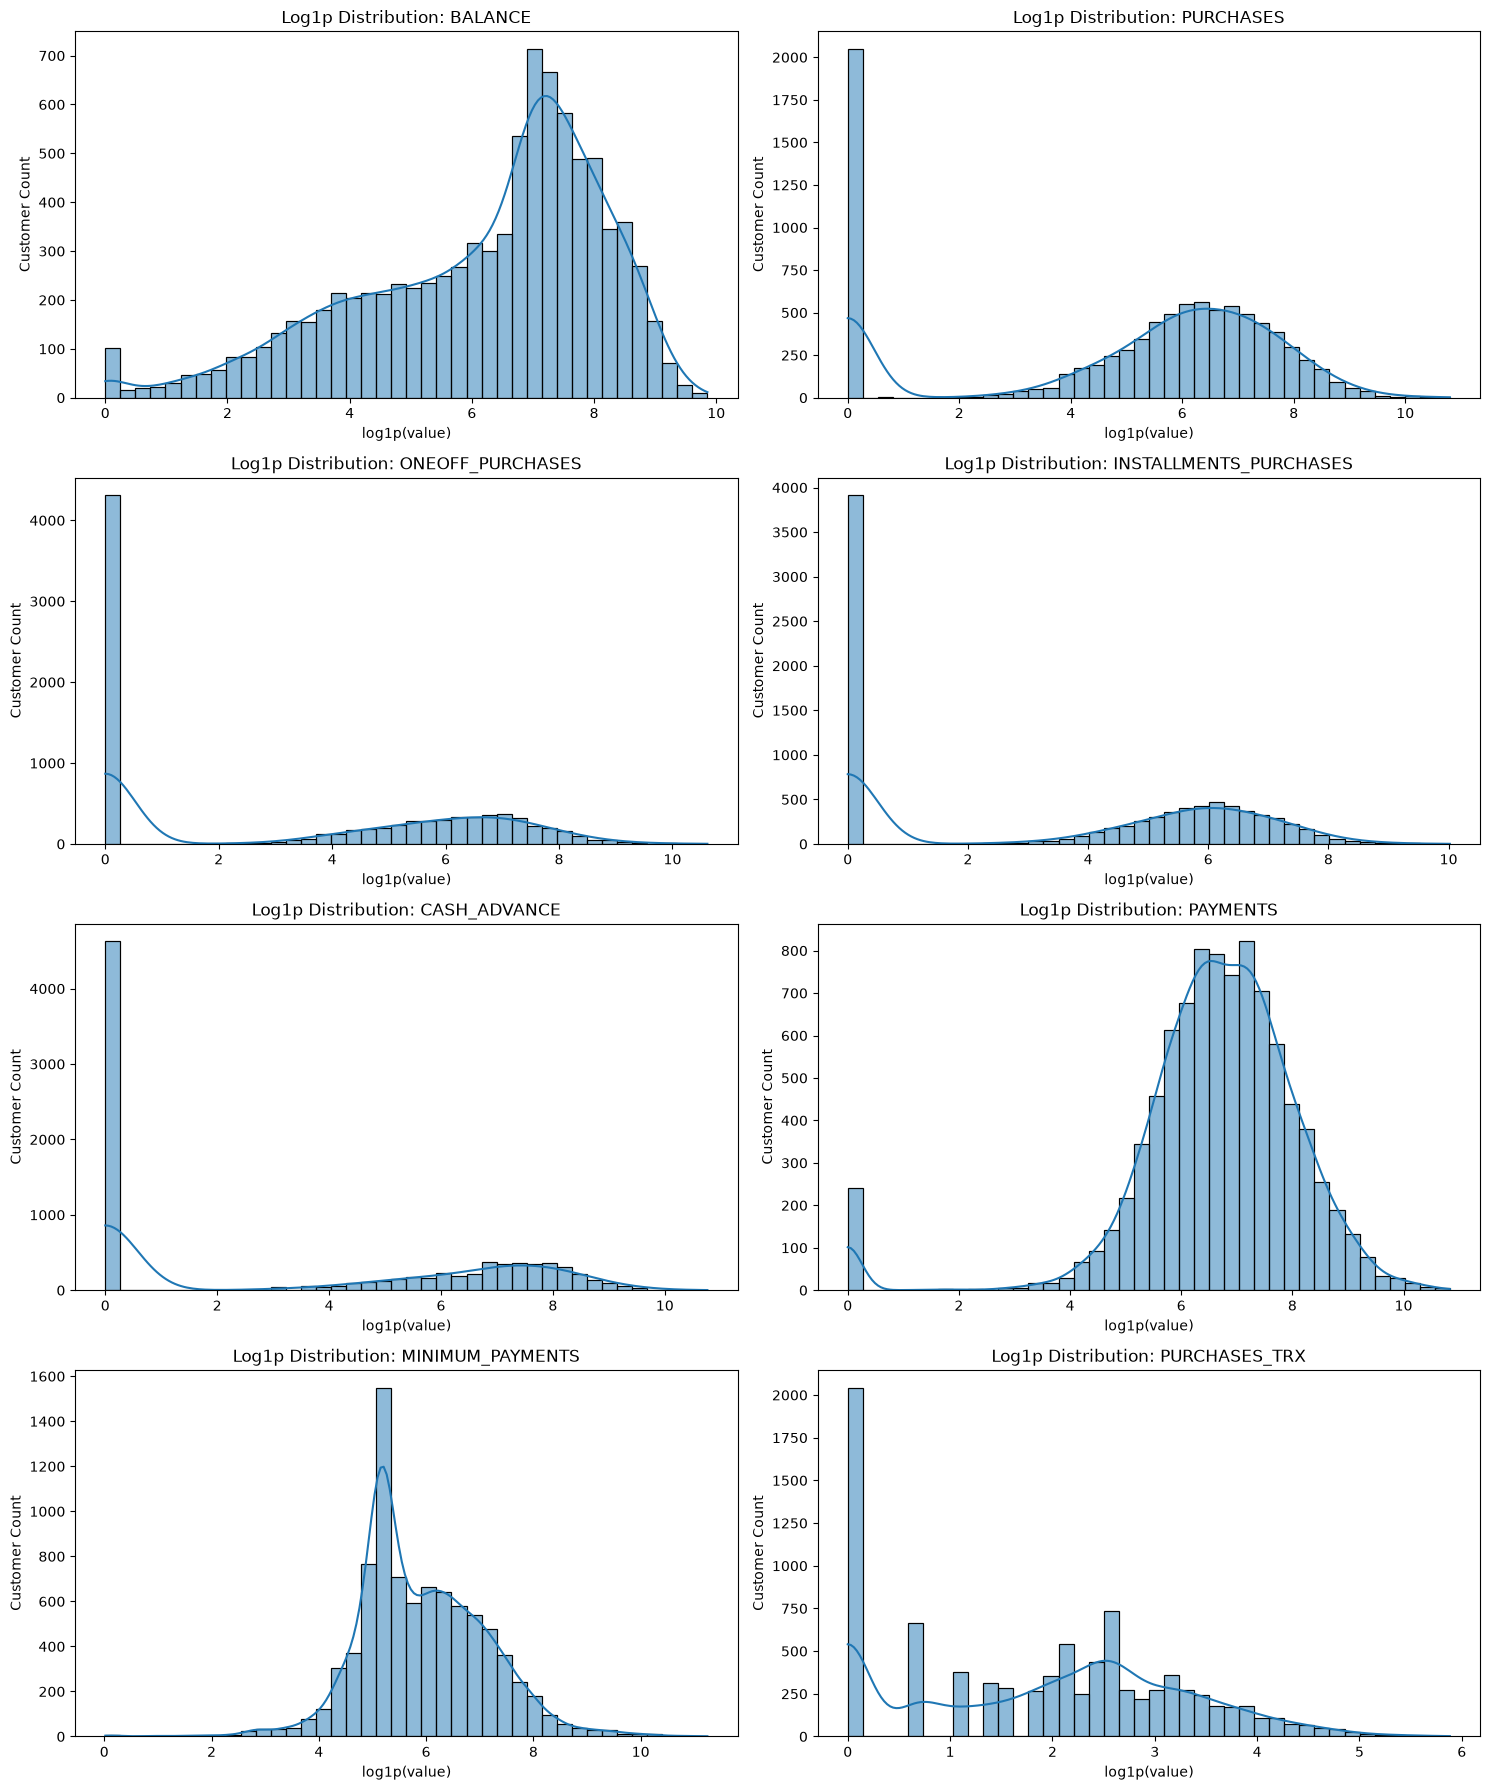

In [4]:
# Features selected for distribution analysis
features = [
    "BALANCE",
    "PURCHASES",
    "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE",
    "PAYMENTS",
    "MINIMUM_PAYMENTS",
    "PURCHASES_TRX"
]

# Create distribution plots
fig, axes = plt.subplots(4, 2, figsize=(15, 18))

for feature, ax in zip(features, axes.flatten()):
    sns.histplot(
        np.log1p(df[feature].dropna()),
        bins=40,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Log1p Distribution: {feature}")
    ax.set_xlabel("log1p(value)")
    ax.set_ylabel("Customer Count")

plt.tight_layout()
plt.show()

## 5. Correlation and Feature Relationship Analysis

This section examines correlations between numerical features and investigates potential redundancy among purchase-related variables.

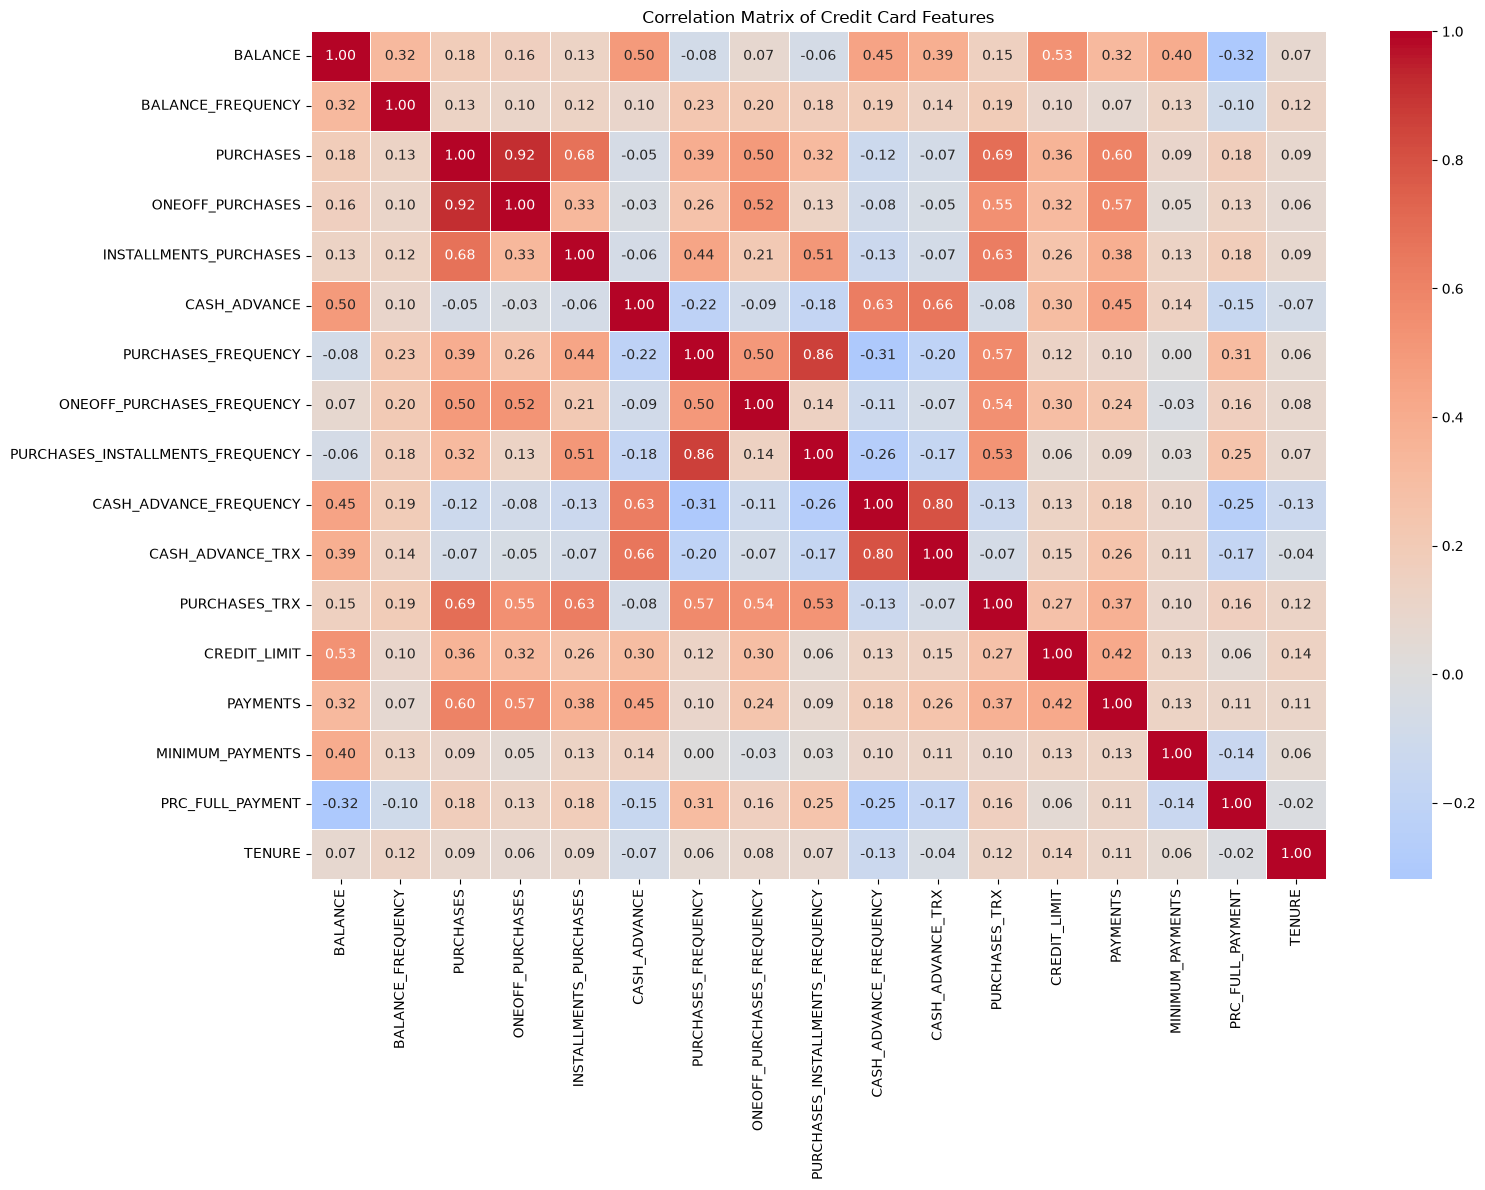

Purchase component relationship:
Mean absolute difference: 0.3001821229050565
Maximum absolute difference: 600.0

Top 15 strongest feature correlations:


Correlation
PURCHASES                        ONEOFF_PURCHASES                     0.916845
PURCHASES_FREQUENCY              PURCHASES_INSTALLMENTS_FREQUENCY     0.862934
CASH_ADVANCE_FREQUENCY           CASH_ADVANCE_TRX                     0.799561
PURCHASES                        PURCHASES_TRX                        0.689561
                                 INSTALLMENTS_PURCHASES               0.679896
CASH_ADVANCE                     CASH_ADVANCE_TRX                     0.656498
                                 CASH_ADVANCE_FREQUENCY               0.628522
INSTALLMENTS_PURCHASES           PURCHASES_TRX                        0.628108
PURCHASES                        PAYMENTS                             0.603264
PURCHASES_FREQUENCY              PURCHASES_TRX                        0.568430
ONEOFF_PURCHASES                 PAYMENTS                             0.567292
                                 PURCHASES_TRX                        0.545523
ONEOFF_PURCHASES_FREQUENCY       PURCHASES_TRX                        0.544869
BALANCE                          CREDIT_LIMIT                         0.531283
PURCHASES_INSTALLMENTS_FREQUENCY PURCHASES_TRX                        0.529975

In [5]:
# Select numerical features, excluding customer ID
numeric_df = df.select_dtypes(include=np.number)

# Correlation matrix
correlation_matrix = numeric_df.corr()

# Correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Credit Card Features")
plt.tight_layout()
plt.show()

# Investigate purchase component relationship
purchase_difference = (
    df["PURCHASES"]
    - df["ONEOFF_PURCHASES"]
    - df["INSTALLMENTS_PURCHASES"]
)

print("Purchase component relationship:")
print("Mean absolute difference:", purchase_difference.abs().mean())
print("Maximum absolute difference:", purchase_difference.abs().max())

# Display strongest feature correlations
correlation_pairs = (
    correlation_matrix.where(
        np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .sort_values(key=abs, ascending=False)
)

print("\nTop 15 strongest feature correlations:")
display(correlation_pairs.head(15).to_frame("Correlation"))

## 6. Purchase Component Consistency Check

Investigate whether total purchases are consistent with the sum of one-off and installment purchases. Identify records with significant differences before making feature-selection decisions.

In [6]:
# Calculate purchase component difference
df["PURCHASE_COMPONENT_DIFF"] = (
    df["PURCHASES"]
    - df["ONEOFF_PURCHASES"]
    - df["INSTALLMENTS_PURCHASES"]
)

# Absolute difference
df["ABS_COMPONENT_DIFF"] = df["PURCHASE_COMPONENT_DIFF"].abs()

# Count records exceeding different tolerances
print("Records with absolute difference > 0.01:",
      (df["ABS_COMPONENT_DIFF"] > 0.01).sum())

print("Records with absolute difference > 1:",
      (df["ABS_COMPONENT_DIFF"] > 1).sum())

print("Records with absolute difference > 100:",
      (df["ABS_COMPONENT_DIFF"] > 100).sum())

# Display records with the largest differences
display(
    df.nlargest(10, "ABS_COMPONENT_DIFF")[
        [
            "CUST_ID",
            "PURCHASES",
            "ONEOFF_PURCHASES",
            "INSTALLMENTS_PURCHASES",
            "PURCHASE_COMPONENT_DIFF",
            "ABS_COMPONENT_DIFF"
        ]
    ]
)

# Remove temporary diagnostic columns
df.drop(
    columns=["PURCHASE_COMPONENT_DIFF", "ABS_COMPONENT_DIFF"],
    inplace=True
)

Records with absolute difference > 0.01: 19
Records with absolute difference > 1: 19
Records with absolute difference > 100: 6


,CUST_ID,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,PURCHASE_COMPONENT_DIFF,ABS_COMPONENT_DIFF
6857,C17045,5629.41,0.00,6229.41,-600.00,600.00
5231,C15378,205.06,0.00,607.76,-402.70,402.70
5967,C16133,279.76,0.00,578.55,-298.79,298.79
6803,C16991,339.11,611.65,12.41,-284.95,284.95
8834,C19075,510.00,0.00,780.00,-270.00,270.00
6790,C16978,426.25,0.00,653.55,-227.30,227.30
5846,C16010,486.27,580.20,0.00,-93.93,93.93
510,C10533,400.41,0.00,489.39,-88.98,88.98
5737,C15897,0.00,0.00,66.95,-66.95,66.95
908,C10940,3393.25,3364.59,77.66,-49.00,49.00


C:\Users\ka100\AppData\Local\Temp\ipykernel_21164\4152152023.py:36: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(


## 7. Outlier Analysis

Identify extreme observations in monetary and transaction-related features using the Interquartile Range (IQR) method.

Outliers will be investigated, not automatically removed.

In [7]:
# Features for outlier investigation
outlier_features = [
    "BALANCE",
    "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE",
    "PAYMENTS",
    "MINIMUM_PAYMENTS",
    "CREDIT_LIMIT",
    "PURCHASES_TRX",
    "CASH_ADVANCE_TRX"
]

outlier_results = []

for feature in outlier_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": feature,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": outlier_count,
        "Outlier Percentage": round(
            outlier_count / len(df) * 100, 2
        )
    })

outlier_report = pd.DataFrame(outlier_results)

display(
    outlier_report.sort_values(
        "Outlier Percentage",
        ascending=False
    )
)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
3,CASH_ADVANCE,-1670.73,2784.55,1030,11.51
1,ONEOFF_PURCHASES,-866.11,1443.51,1013,11.32
2,INSTALLMENTS_PURCHASES,-702.96,1171.59,867,9.69
5,MINIMUM_PAYMENTS,-815.42,1810.03,841,9.40
4,PAYMENTS,-1893.51,4177.92,808,9.03
8,CASH_ADVANCE_TRX,-6.00,10.00,804,8.98
7,PURCHASES_TRX,-23.00,41.00,766,8.56
0,BALANCE,-2760.51,4942.93,695,7.77
6,CREDIT_LIMIT,-5750.00,13850.00,248,2.77


## 8. Boxplot Analysis of Customer Spending

Visualise the monetary and transaction features to understand the spread of values and extreme observations.

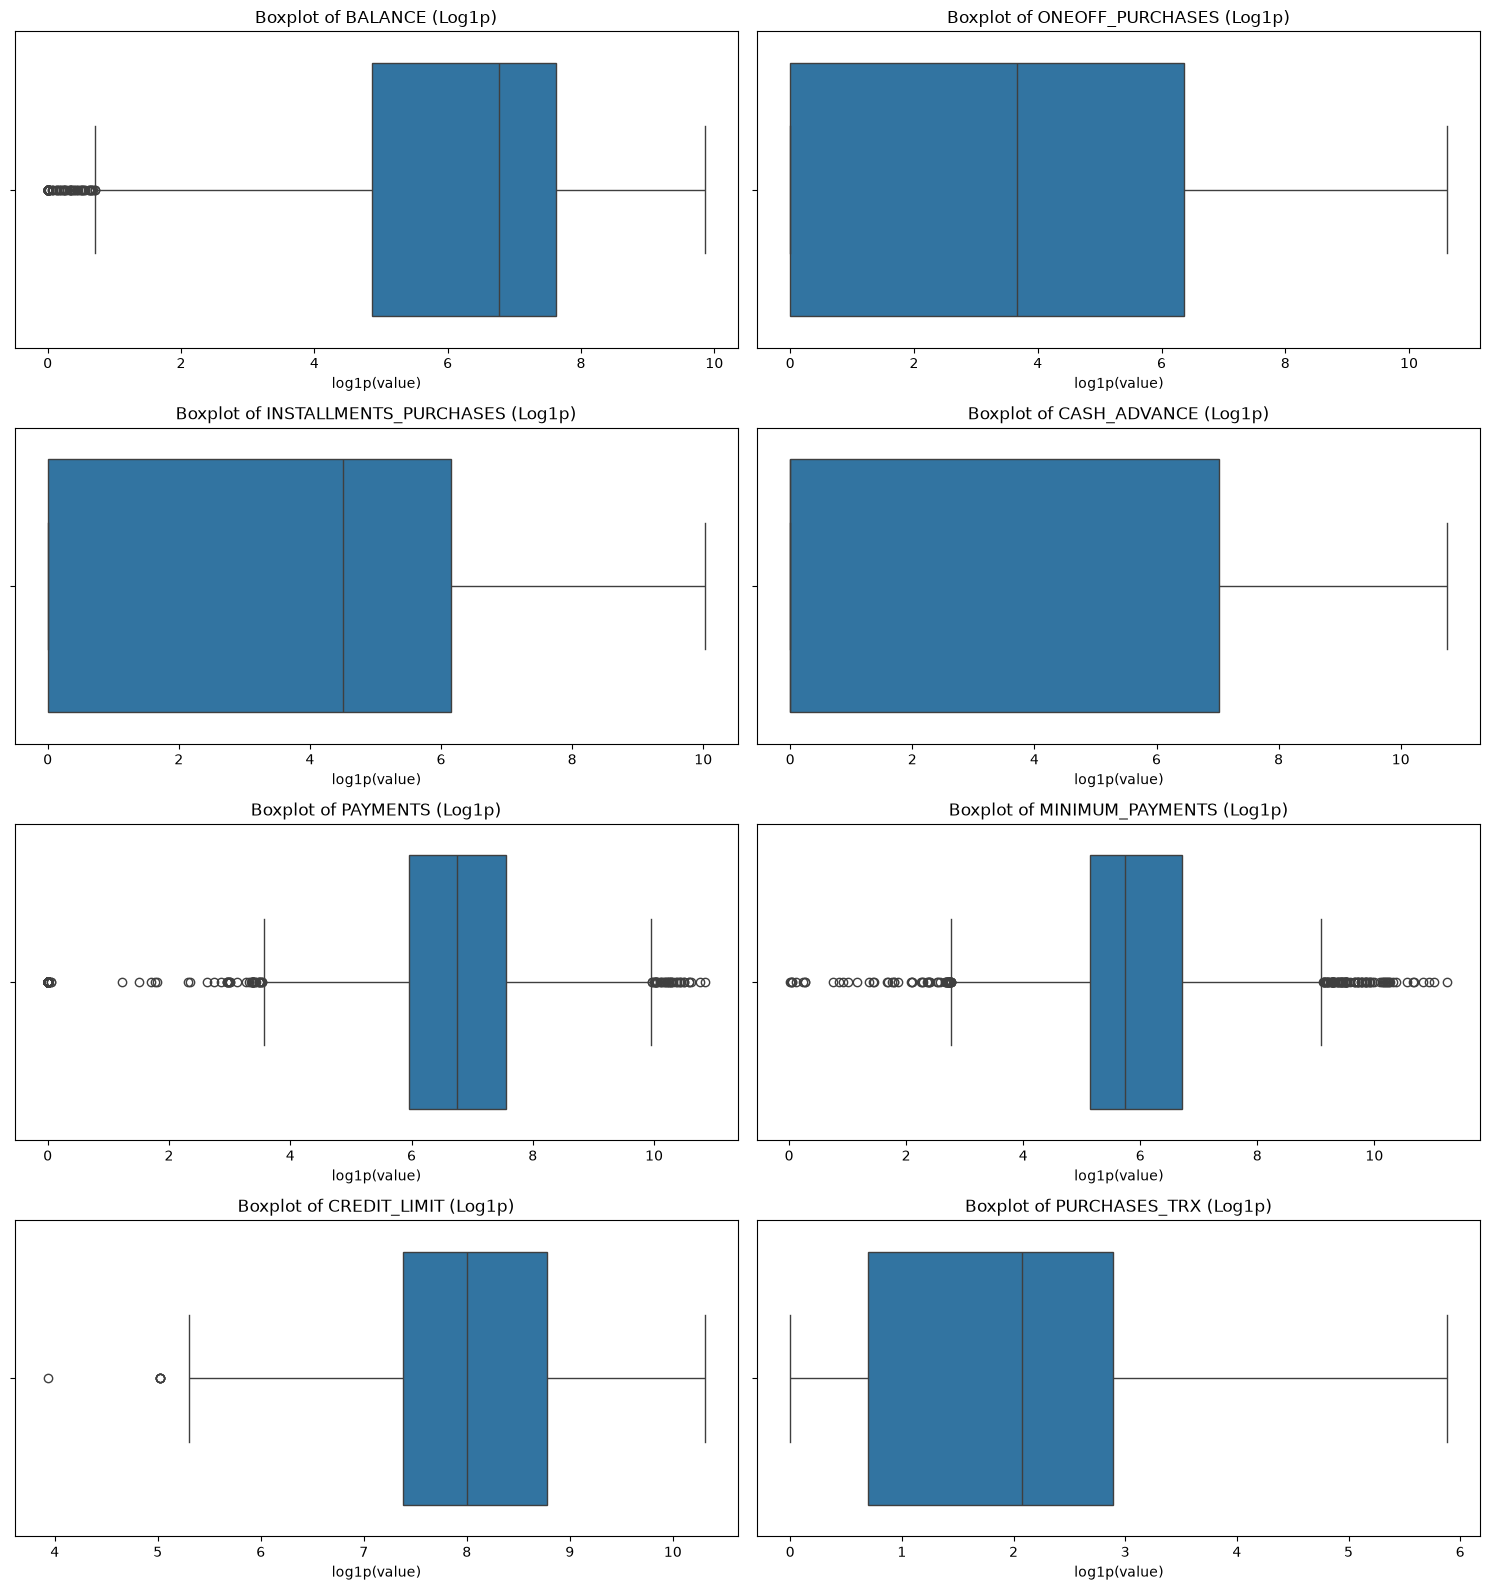

In [8]:
# Features selected for boxplot analysis
boxplot_features = [
    "BALANCE",
    "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE",
    "PAYMENTS",
    "MINIMUM_PAYMENTS",
    "CREDIT_LIMIT",
    "PURCHASES_TRX"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 16))

for feature, ax in zip(boxplot_features, axes.flatten()):
    sns.boxplot(
        x=np.log1p(df[feature]),
        ax=ax
    )
    ax.set_title(f"Boxplot of {feature} (Log1p)")
    ax.set_xlabel("log1p(value)")

plt.tight_layout()
plt.show()

## 9. Feature Range and Data Validity Checks

Validate numerical feature ranges, investigate unusual frequency values, and examine records containing missing values.

In [9]:
# 1. Check negative values in non-negative features
non_negative_features = [
    "BALANCE",
    "PURCHASES",
    "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE",
    "CREDIT_LIMIT",
    "PAYMENTS",
    "MINIMUM_PAYMENTS",
    "CASH_ADVANCE_TRX",
    "PURCHASES_TRX"
]

print("NEGATIVE VALUE COUNTS")

for feature in non_negative_features:
    count = (df[feature] < 0).sum()
    print(f"{feature}: {count}")

# 2. Investigate frequency features
frequency_features = [
    "BALANCE_FREQUENCY",
    "PURCHASES_FREQUENCY",
    "ONEOFF_PURCHASES_FREQUENCY",
    "PURCHASES_INSTALLMENTS_FREQUENCY",
    "CASH_ADVANCE_FREQUENCY",
    "PRC_FULL_PAYMENT"
]

print("\nFREQUENCY FEATURE RANGES")

display(df[frequency_features].describe().T)

# 3. Inspect unusual cash advance frequency values
unusual_frequency = df[
    df["CASH_ADVANCE_FREQUENCY"] > 1
]

print("\nCASH ADVANCE FREQUENCY ABOVE 1:")
print("Count:", len(unusual_frequency))

display(
    unusual_frequency[
        ["CUST_ID", "CASH_ADVANCE_FREQUENCY",
         "CASH_ADVANCE", "CASH_ADVANCE_TRX", "TENURE"]
    ].head(15)
)

# 4. Inspect missing-value records
print("\nMISSING VALUE RECORDS")

display(
    df[df.isnull().any(axis=1)][
        ["CUST_ID", "CREDIT_LIMIT", "MINIMUM_PAYMENTS"]
    ].head(15)
)

NEGATIVE VALUE COUNTS
BALANCE: 0
PURCHASES: 0
ONEOFF_PURCHASES: 0
INSTALLMENTS_PURCHASES: 0
CASH_ADVANCE: 0
CREDIT_LIMIT: 0
PAYMENTS: 0
MINIMUM_PAYMENTS: 0
CASH_ADVANCE_TRX: 0
PURCHASES_TRX: 0

FREQUENCY FEATURE RANGES


,count,mean,std,min,25%,50%,75%,max
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.0,0.888889,1.000000,1.000000,1.0
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.0,0.083333,0.500000,0.916667,1.0
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.0,0.000000,0.083333,0.300000,1.0
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.0,0.000000,0.166667,0.750000,1.0
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.0,0.000000,0.000000,0.222222,1.5
PRC_FULL_PAYMENT,8950.0,0.153715,0.292499,0.0,0.000000,0.000000,0.142857,1.0



CASH ADVANCE FREQUENCY ABOVE 1:
Count: 8


,CUST_ID,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE,CASH_ADVANCE_TRX,TENURE
681,C10708,1.250000,7240.433194,12,8
1626,C11680,1.166667,3719.650168,24,6
2555,C12629,1.125000,1651.286918,12,8
2608,C12684,1.100000,4109.465221,20,10
3038,C13127,1.500000,1932.460679,18,6
3253,C13347,1.166667,2794.326341,10,6
8055,C18273,1.090909,6084.858872,28,11
8365,C18588,1.142857,2127.213754,26,7



MISSING VALUE RECORDS


,CUST_ID,CREDIT_LIMIT,MINIMUM_PAYMENTS
3,C10004,7500.0,NaN
45,C10047,2400.0,NaN
47,C10049,4200.0,NaN
54,C10056,1000.0,NaN
55,C10057,6000.0,NaN
56,C10058,4000.0,NaN
63,C10065,1600.0,NaN
93,C10098,2400.0,NaN
94,C10099,2400.0,NaN
97,C10102,4000.0,NaN


## 10. Missing Value Pattern Analysis

Examine the distribution and overlap of missing values in CREDIT_LIMIT and MINIMUM_PAYMENTS. Evaluate median imputation as a potential treatment.

In [10]:
# 1. Missing-value summary
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_summary[missing_summary["Missing Count"] > 0])

# 2. Check overlap between missing columns
credit_missing = df["CREDIT_LIMIT"].isna()
minimum_missing = df["MINIMUM_PAYMENTS"].isna()

print("Missing in MINIMUM_PAYMENTS:", minimum_missing.sum())
print("Missing in CREDIT_LIMIT:", credit_missing.sum())
print("Missing in both columns:", (credit_missing & minimum_missing).sum())
print("Missing only in MINIMUM_PAYMENTS:", (minimum_missing & ~credit_missing).sum())
print("Missing only in CREDIT_LIMIT:", (credit_missing & ~minimum_missing).sum())

# 3. Examine MINIMUM_PAYMENTS distribution
print("\nMINIMUM_PAYMENTS STATISTICS")
display(df["MINIMUM_PAYMENTS"].describe())

print("Median MINIMUM_PAYMENTS:",
      df["MINIMUM_PAYMENTS"].median())

# 4. Examine CREDIT_LIMIT distribution
print("\nCREDIT_LIMIT STATISTICS")
display(df["CREDIT_LIMIT"].describe())

print("Median CREDIT_LIMIT:",
      df["CREDIT_LIMIT"].median())

,Missing Count,Missing Percentage
CREDIT_LIMIT,1,0.01
MINIMUM_PAYMENTS,313,3.50


Missing in MINIMUM_PAYMENTS: 313
Missing in CREDIT_LIMIT: 1
Missing in both columns: 0
Missing only in MINIMUM_PAYMENTS: 313
Missing only in CREDIT_LIMIT: 1

MINIMUM_PAYMENTS STATISTICS


count     8637.000000
mean       864.206542
std       2372.446607
min          0.019163
25%        169.123707
50%        312.343947
75%        825.485459
max      76406.207520
Name: MINIMUM_PAYMENTS, dtype: float64

Median MINIMUM_PAYMENTS: 312.343947

CREDIT_LIMIT STATISTICS


count     8949.000000
mean      4494.449450
std       3638.815725
min         50.000000
25%       1600.000000
50%       3000.000000
75%       6500.000000
max      30000.000000
Name: CREDIT_LIMIT, dtype: float64

Median CREDIT_LIMIT: 3000.0


# 11. Exploratory Data Analysis — Key Findings

## Dataset Overview
- Total customers: 8,950
- Total columns: 18
- Customer identifier: CUST_ID
- Exact duplicate records: 0

## Data Quality
- Missing MINIMUM_PAYMENTS: 313 (3.50%)
- Missing CREDIT_LIMIT: 1 (0.01%)
- Negative numerical values: None detected
- Unusual CASH_ADVANCE_FREQUENCY values above 1: 8

## Distribution Analysis
- Most monetary features exhibit positive skewness.
- Log1p transformations improve the visualisation of monetary distributions.
- Several spending features contain a large number of zero values.

## Correlation Analysis
- PURCHASES and ONEOFF_PURCHASES: correlation approximately 0.92.
- PURCHASES_FREQUENCY and PURCHASES_INSTALLMENTS_FREQUENCY: approximately 0.86.
- CASH_ADVANCE_FREQUENCY and CASH_ADVANCE_TRX: approximately 0.80.

## Outlier Analysis
- Several monetary and transaction features contain statistical outliers.
- Outliers will be retained initially because they may represent genuine customer behaviour.

## Proposed Preprocessing
1. Retain CUST_ID separately for customer identification.
2. Investigate redundant features before final feature selection.
3. Impute missing numerical values using the median.
4. Apply log1p transformation to suitable skewed features.
5. Standardise numerical features before K-Means clustering.
6. Compare clustering quality and interpretability during model evaluation.

## Conclusion
The dataset is suitable for customer segmentation after appropriate preprocessing. It contains diverse spending patterns, payment behaviours, and transaction frequencies that can help identify meaningful customer groups.